# emcee — primeri iz dokumentacije

Notebook prati [dokumentaciju biblioteke emcee](https://emcee.readthedocs.io/en/stable/). Kod iz tutorijala je zadržan, a dodati su teorijski pregledi, komentari na srpskom i dodatne provere.

**Instalacija:**
```
pip install emcee corner h5py tqdm
```
- `emcee` — sampler
- `corner` — „trougaoni” grafik posteriora
- `h5py` — čuvanje lanca u fajl (deo 5)
- `tqdm` — traka napretka (`progress=True`)

**Sadržaj**
| Deo | Tutorijal | Sadržaj |
|---|---|---|
| 1 | Quickstart | uzorkovanje 5D Gausove raspodele, osnovni API |
| 2 | Fitting a model to data | linija sa potcenjenim greškama: najmanji kvadrati → maksimalna verodostojnost → emcee |
| 3 | Autocorrelation | vreme autokorelacije τ i njegova zavisnost od dužine lanca |
| 4 | Dodatak | Hogg-ov mešavinski model (autlajeri) sa emcee |
| 5 | Saving & monitoring | čuvanje u fajl, automatsko zaustavljanje, blobs |
| 6 | Parallelization | više procesora |
| 7 | Moves | alternativni potezi na posterioru sa dva maksimuma |
| 8 | — | rezime i opšti šablon |

**Osnovni pojmovi**
- emcee zahteva **ln posterior** = ln prior + ln verodostojnost (logaritam, ne samu verovatnoću).
- **Šetač (walker)** je jedna tačka u prostoru parametara; ansambl šetača zajedno istražuje posterior.
- Oblik lanca je `(koraci, šetači, parametri)`; `flat=True` spaja šetače u jednu tabelu uzoraka.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
print("emcee verzija:", emcee.__version__)

try:
    import corner          # za corner plot; ako nije instaliran, ti grafici se preskaču
    IMA_CORNER = True
except ImportError:
    IMA_CORNER = False
    print("corner nije instaliran: pip install corner")

plt.rcParams["figure.figsize"] = (7, 4.5)

emcee verzija: 3.1.6


## 1. Quickstart — uzorkovanje 5D Gausove raspodele

- Ciljna raspodela je poznata unapred, pa služi kao provera da li sampler radi ispravno.
- Gustina: $p(\vec x) \propto \exp\left[-\tfrac12 (\vec x-\vec\mu)^\top \Sigma^{-1} (\vec x-\vec\mu)\right]$ — Gausova raspodela u 5 dimenzija.
- Funkcija `log_prob` za proizvoljan položaj vraća logaritam (nenormalizovane) gustine verovatnoće.

In [2]:
def log_prob(x, mu, cov):
    # x  = položaj JEDNOG šetača (niz od 5 brojeva)
    # mu, cov = fiksni podaci; emcee ih prosleđuje preko args
    diff = x - mu
    return -0.5 * np.dot(diff, np.linalg.solve(cov, diff))   # solve(cov, diff) = cov^{-1} · diff

ndim = 5
np.random.seed(42)                       # ponovljivi rezultati
means = np.random.rand(ndim)             # prava sredina μ (cilj je da se dobije uzorkovanjem)
cov = 0.5 - np.random.rand(ndim**2).reshape((ndim, ndim))
cov = np.triu(cov)
cov += cov.T - np.diag(cov.diagonal())   # simetrična matrica
cov = np.dot(cov, cov)                   # pozitivno definitna -> ispravna kovarijansa
print("Prave sredine μ:", np.round(means, 3))

Prave sredine μ: [0.375 0.951 0.732 0.599 0.156]


In [3]:
nwalkers = 32
p0 = np.random.rand(nwalkers, ndim)      # 32 šetača x 5 parametara, grubi start između 0 i 1
print("Oblik p0:", p0.shape)

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_prob, args=[means, cov])

# Provera: emcee će zvati log_prob(x, means, cov)
print("log_prob prvog šetača na startu:", log_prob(p0[0], means, cov))

Oblik p0: (32, 5)
log_prob prvog šetača na startu: -2.596094589085444


In [4]:
# Zagrevanje (burn-in): 100 koraka da se šetači rasporede, pa brisanje istorije
state = sampler.run_mcmc(p0, 100)        # state = gde su šetači stali
sampler.reset()                          # briše zapamćene korake (zato je state sačuvan)

# Pravo pokretanje: 10.000 koraka od mesta gde je zagrevanje stalo
sampler.run_mcmc(state, 10000, progress=True);

  0%|          | 0/10000 [00:00<?, ?it/s]

  1%|▏         | 145/10000 [00:00<00:06, 1445.60it/s]

  3%|▎         | 303/10000 [00:00<00:06, 1520.85it/s]

  5%|▍         | 456/10000 [00:00<00:06, 1515.47it/s]

  6%|▌         | 608/10000 [00:00<00:06, 1498.75it/s]

  8%|▊         | 758/10000 [00:00<00:06, 1364.48it/s]

... (48 outputs left out)

 95%|█████████▍| 9461/10000 [00:05<00:00, 2052.91it/s]

 97%|█████████▋| 9669/10000 [00:06<00:00, 2034.09it/s]

 99%|█████████▊| 9874/10000 [00:06<00:00, 1943.47it/s]

100%|██████████| 10000/10000 [00:06<00:00, 1605.45it/s]

Oblik get_chain(): (10000, 32, 5)  -> (koraci, šetači, parametri)
Oblik flat=True:    (320000, 5)  -> (uzorci, parametri)


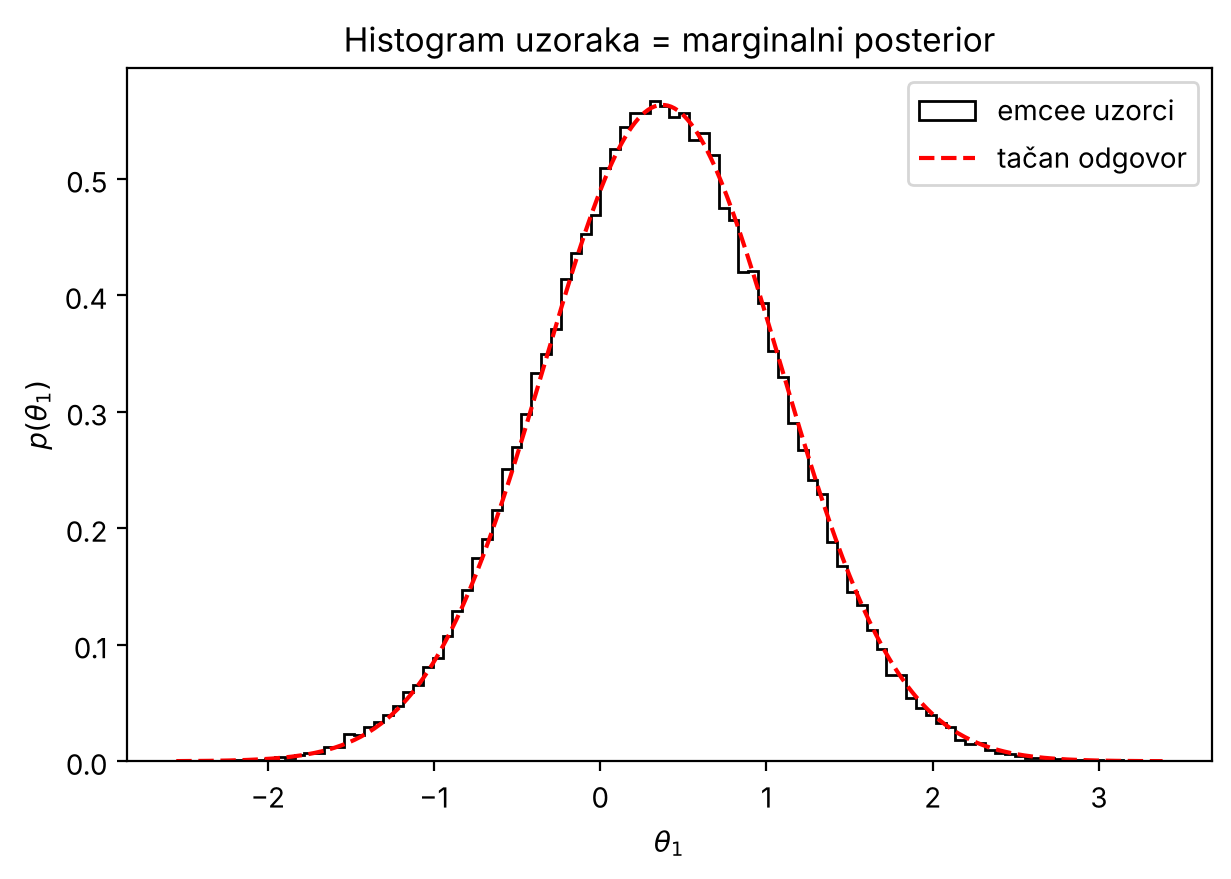

In [5]:
chain = sampler.get_chain()
print("Oblik get_chain():", chain.shape, " -> (koraci, šetači, parametri)")
samples = sampler.get_chain(flat=True)
print("Oblik flat=True:   ", samples.shape, " -> (uzorci, parametri)")

plt.hist(samples[:, 0], 100, color="k", histtype="step", density=True, label="emcee uzorci")
# Poređenje sa tačnim odgovorom: marginala Gausove raspodele je Gaus sa sredinom μ0 i varijansom cov[0,0]
t = np.linspace(samples[:, 0].min(), samples[:, 0].max(), 300)
plt.plot(t, np.exp(-(t-means[0])**2/(2*cov[0,0]))/np.sqrt(2*np.pi*cov[0,0]), "r--", label="tačan odgovor")
plt.xlabel(r"$\theta_1$"); plt.ylabel(r"$p(\theta_1)$"); plt.legend()
plt.title("Histogram uzoraka = marginalni posterior"); plt.show()

In [6]:
print("Sredine iz uzoraka:", np.round(samples.mean(axis=0), 3))
print("Prave sredine μ:   ", np.round(means, 3))
print(f"Prosečna stopa prihvatanja: {np.mean(sampler.acceptance_fraction):.3f}   (tipično 0.2–0.5; problem je samo blizu 0 ili 1)")
print(f"Prosečno vreme autokorelacije τ: {np.mean(sampler.get_autocorr_time()):.1f} koraka")
print(f"Lanac je dug 10000 koraka = {10000/np.max(sampler.get_autocorr_time()):.0f} τ  (treba > 50)")

Sredine iz uzoraka: [0.357 0.955 0.742 0.592 0.148]
Prave sredine μ:    [0.375 0.951 0.732 0.599 0.156]
Prosečna stopa prihvatanja: 0.552   (tipično 0.2–0.5; problem je samo blizu 0 ili 1)


Prosečno vreme autokorelacije τ: 57.1 koraka


Lanac je dug 10000 koraka = 170 τ  (treba > 50)


## 2. Fitting a model to data — linija sa potcenjenim greškama

- Problem je isti kao u Hogg-ovom radu, uz jednu razliku: prijavljene greške `yerr` su **premale**.
- Stvarni šum ima i dodatnu komponentu srazmernu samoj vrednosti y, sa nepoznatim faktorom **f**.
- Postupak: (a) najmanji kvadrati → (b) maksimalna verodostojnost sa f → (c) emcee za procenu nesigurnosti.

### 2a. Generativni model i sintetički podaci

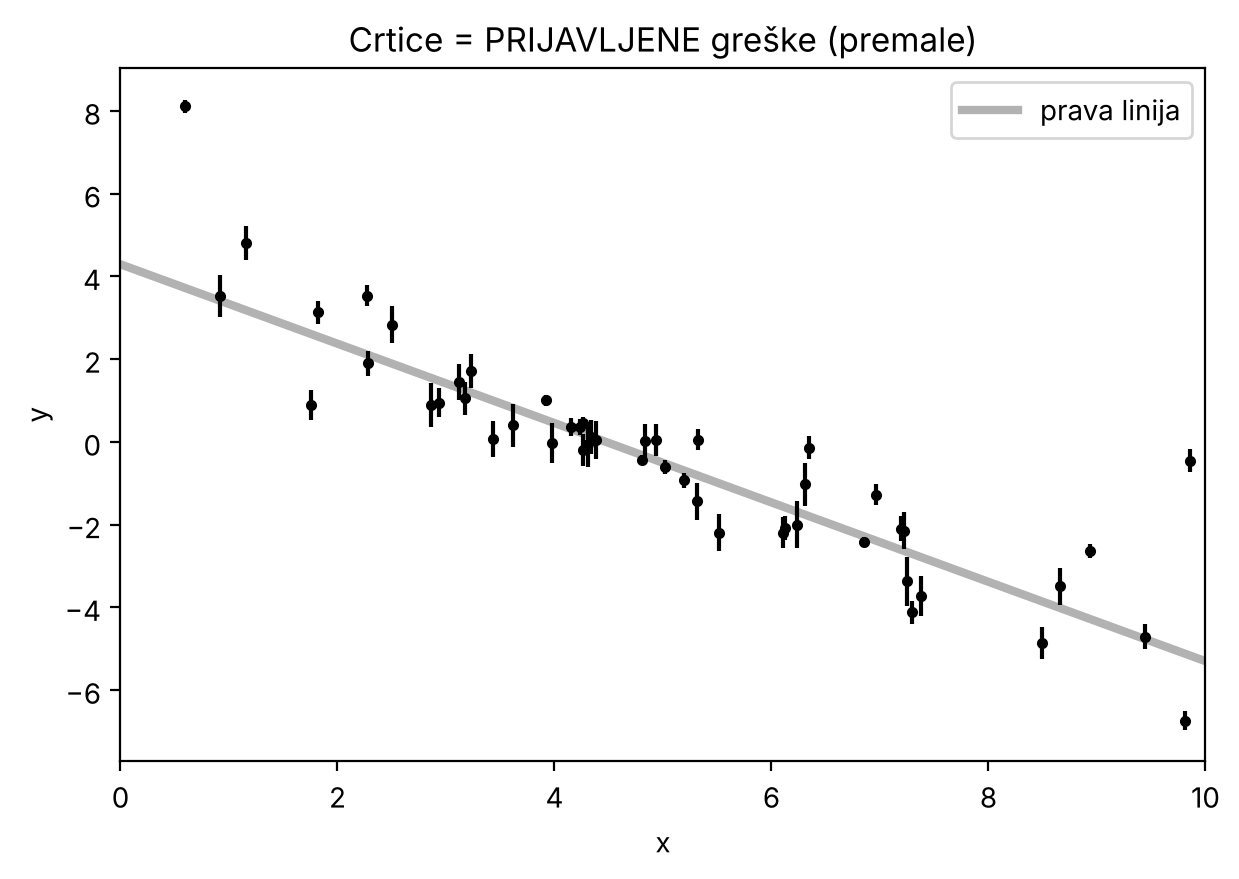

In [7]:
np.random.seed(123)

# "Prave" vrednosti (u realnom problemu nepoznate; ovde služe za proveru rezultata)
m_true, b_true, f_true = -0.9594, 4.294, 0.534

# Generativni model = recept za podatke:
N = 50
x = np.sort(10 * np.random.rand(N))                  # 1) izbor x
yerr = 0.1 + 0.5 * np.random.rand(N)                 # 2) PRIJAVLJENE greške (ono što analitičar vidi)
y = m_true * x + b_true                              # 3) prava linija
y += np.abs(f_true * y) * np.random.randn(N)         # 4) SKRIVENI šum, srazmeran y
y += yerr * np.random.randn(N)                       # 5) prijavljeni šum

x0 = np.linspace(0, 10, 500)
plt.errorbar(x, y, yerr=yerr, fmt=".k", capsize=0)
plt.plot(x0, m_true * x0 + b_true, "k", alpha=0.3, lw=3, label="prava linija")
plt.xlim(0, 10); plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.title("Crtice = PRIJAVLJENE greške (premale)"); plt.show()

### 2b. Najmanji kvadrati (uz pretpostavku da su prijavljene greške tačne)

Postupak je isti kao Vežba 1 iz Hogg-ovog rada. `np.vander(x, 2)` pravi matricu A sa kolonama [x, 1], pa je rezultat w = [m, b].

In [8]:
A = np.vander(x, 2)
C = np.diag(yerr * yerr)
ATA = np.dot(A.T, A / (yerr**2)[:, None])          # A^T C^-1 A
cov_ls = np.linalg.inv(ATA)                          # kovarijansa parametara
w = np.linalg.solve(ATA, np.dot(A.T, y / yerr**2))   # najbolji [m, b]
print("Najmanji kvadrati:")
print(f"m = {w[0]:.3f} ± {np.sqrt(cov_ls[0, 0]):.3f}   (prava: {m_true})")
print(f"b = {w[1]:.3f} ± {np.sqrt(cov_ls[1, 1]):.3f}   (prava: {b_true})")
print(f"-> m je {(w[0]-m_true)/np.sqrt(cov_ls[0,0]):.0f} 'sigmi' od prave vrednosti: pogrešno I samouvereno!")

Najmanji kvadrati:
m = -1.104 ± 0.016   (prava: -0.9594)
b = 5.441 ± 0.091   (prava: 4.294)
-> m je -9 'sigmi' od prave vrednosti: pogrešno I samouvereno!


### 2c. Maksimalna verodostojnost sa parametrom f

Varijansa svake tačke: $s_n^2 = \sigma_n^2 + f^2 (m x_n + b)^2$.
- Koristi se **ln f** umesto f, pa je f = exp(ln f) uvek pozitivno.
- Član `np.log(sigma2)` je **neophodan**; bez njega bi optimizacija vodila f u beskonačnost.

In [9]:
def log_likelihood(theta, x, y, yerr):
    m, b, log_f = theta
    model = m * x + b
    sigma2 = yerr**2 + model**2 * np.exp(2 * log_f)      # ukupna varijansa
    return -0.5 * np.sum((y - model) ** 2 / sigma2 + np.log(sigma2))

from scipy.optimize import minimize
np.random.seed(42)
nll = lambda *args: -log_likelihood(*args)              # optimizator traži minimum, pa se menja znak
initial = np.array([m_true, b_true, np.log(f_true)]) + 0.1 * np.random.randn(3)
soln = minimize(nll, initial, args=(x, y, yerr))
m_ml, b_ml, log_f_ml = soln.x
print("Maksimalna verodostojnost:")
print(f"m = {m_ml:.3f}, b = {b_ml:.3f}, f = {np.exp(log_f_ml):.3f}")
print("-> Bliže istini, ali BEZ nesigurnosti. Zato MCMC.")

Maksimalna verodostojnost:
m = -1.003, b = 4.528, f = 0.454
-> Bliže istini, ali BEZ nesigurnosti. Zato MCMC.


### 2d. Prior i ln posterior

**ln posterior = ln prior + ln verodostojnost**
- Ravan prior sa granicama: unutar dozvoljenog opsega vraća 0.0 (= ln 1), izvan njega `-np.inf` (= ln 0).

In [10]:
def log_prior(theta):
    m, b, log_f = theta
    if -5.0 < m < 0.5 and 0.0 < b < 10.0 and -10.0 < log_f < 1.0:
        return 0.0
    return -np.inf

def log_probability(theta, x, y, yerr):
    lp = log_prior(theta)
    if not np.isfinite(lp):          # van granica priora verodostojnost se ne računa
        return -np.inf
    return lp + log_likelihood(theta, x, y, yerr)

# Provera pre MCMC-a: na maksimumu mora biti konačan broj
print("ln posterior na maksimumu:", log_probability(soln.x, x, y, yerr))
print("ln posterior van granica: ", log_probability([1.0, 4.0, 0.0], x, y, yerr))

ln posterior na maksimumu: -12.18241394801543
ln posterior van granica:  -inf


### 2e. Pokretanje emcee-ja

Šetači počinju u **maloj okolini** maksimuma verodostojnosti. Ne smeju svi početi iz iste tačke, jer se tada stretch potez ne bi pomerio.

In [11]:
pos = soln.x + 1e-4 * np.random.randn(32, 3)    # 32 šetača, 3 parametra
nwalkers, ndim = pos.shape

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability, args=(x, y, yerr))
sampler.run_mcmc(pos, 5000, progress=True);

  0%|          | 0/5000 [00:00<?, ?it/s]

  4%|▎         | 178/5000 [00:00<00:02, 1778.80it/s]

  7%|▋         | 356/5000 [00:00<00:03, 1462.31it/s]

 10%|█         | 506/5000 [00:00<00:03, 1230.30it/s]

 13%|█▎        | 634/5000 [00:00<00:03, 1142.92it/s]

 15%|█▌        | 751/5000 [00:00<00:03, 1092.59it/s]

... (30 outputs left out)

 91%|█████████▏| 4566/5000 [00:03<00:00, 1700.69it/s]

 95%|█████████▍| 4737/5000 [00:03<00:00, 1615.15it/s]

 99%|█████████▊| 4932/5000 [00:04<00:00, 1709.28it/s]

100%|██████████| 5000/5000 [00:04<00:00, 1231.23it/s]

### 2f. Trace plot — provera stabilizacije lanca

Stabilizovan lanac izgleda kao gusta traka bez trenda. Ako se traka još pomera naviše ili naniže, faza zagrevanja nije završena.

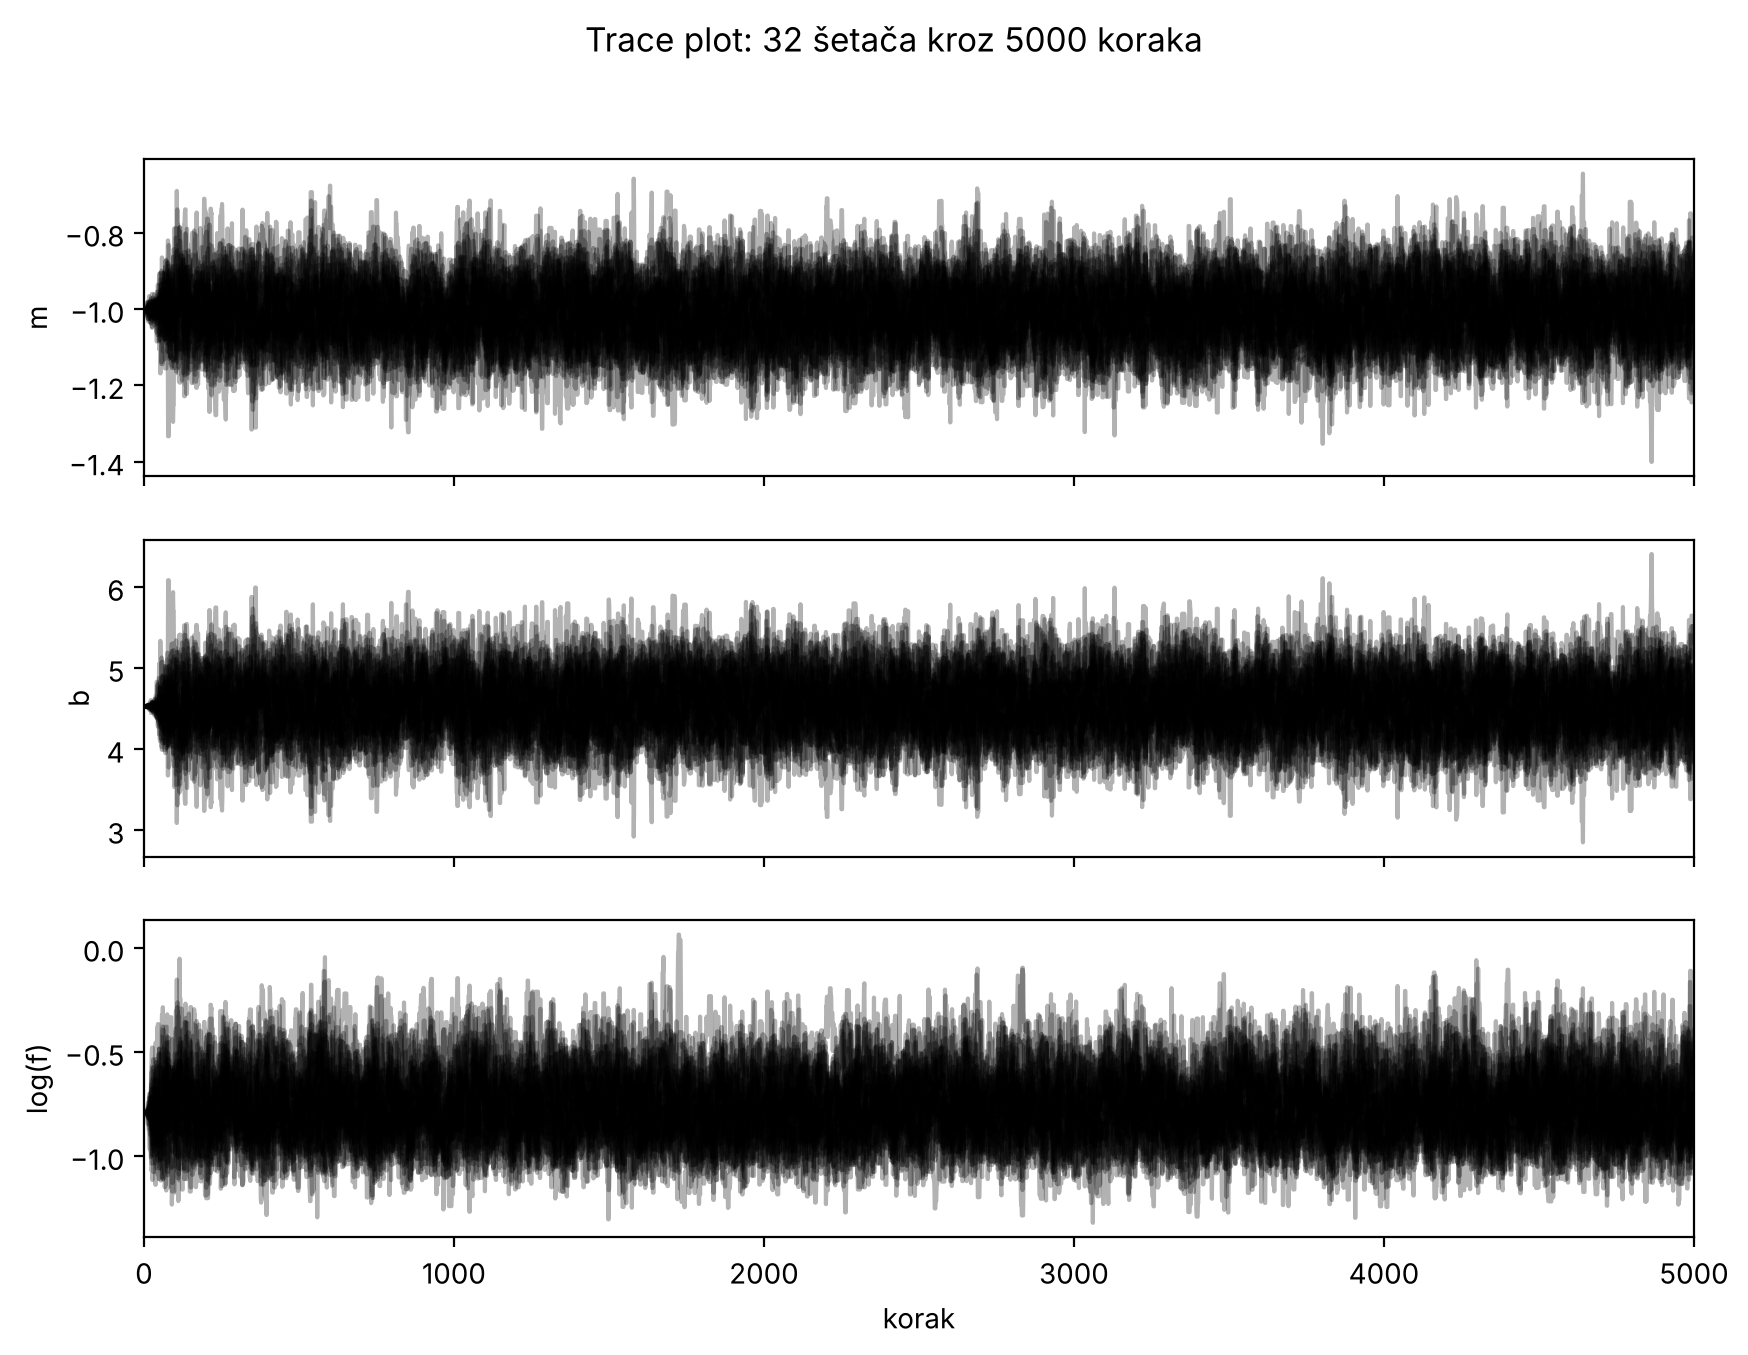

In [12]:
fig, axes = plt.subplots(3, figsize=(10, 7), sharex=True)
samples = sampler.get_chain()
labels = ["m", "b", "log(f)"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)    # svaka linija = jedan šetač
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
axes[-1].set_xlabel("korak")
plt.suptitle("Trace plot: 32 šetača kroz 5000 koraka"); plt.show()

In [13]:
tau = sampler.get_autocorr_time()
print("τ za [m, b, log f]:", np.round(tau, 1))
print(f"Lanac = {5000/np.max(tau):.0f} τ  (potrebno > 50)")
print(f"Stopa prihvatanja: {np.mean(sampler.acceptance_fraction):.2f}")

τ za [m, b, log f]: [37.5 37.8 40.2]
Lanac = 124 τ  (potrebno > 50)
Stopa prihvatanja: 0.65


### 2g. discard, thin, flat

| argument | značenje | pravilo |
|---|---|---|
| `discard` | odbacivanje prvih koraka (zagrevanje) | nekoliko τ |
| `thin` | zadržavanje svakog k-tog koraka | ≈ τ/2 |
| `flat` | spajanje šetača | za histograme |

In [14]:
flat_samples = sampler.get_chain(discard=100, thin=15, flat=True)
print("Oblik:", flat_samples.shape)
print(f"Provera: (5000-100)/15 ≈ {flat_samples.shape[0]//32} zadržanih koraka × 32 šetača = {flat_samples.shape[0]}")

Oblik: (10432, 3)
Provera: (5000-100)/15 ≈ 326 zadržanih koraka × 32 šetača = 10432


### 2h. Corner plot

Na dijagonali su histogrami pojedinačnih parametara (marginalizovani posterior), a ispod dijagonale parovi parametara (korelacije). Linije označavaju prave vrednosti.

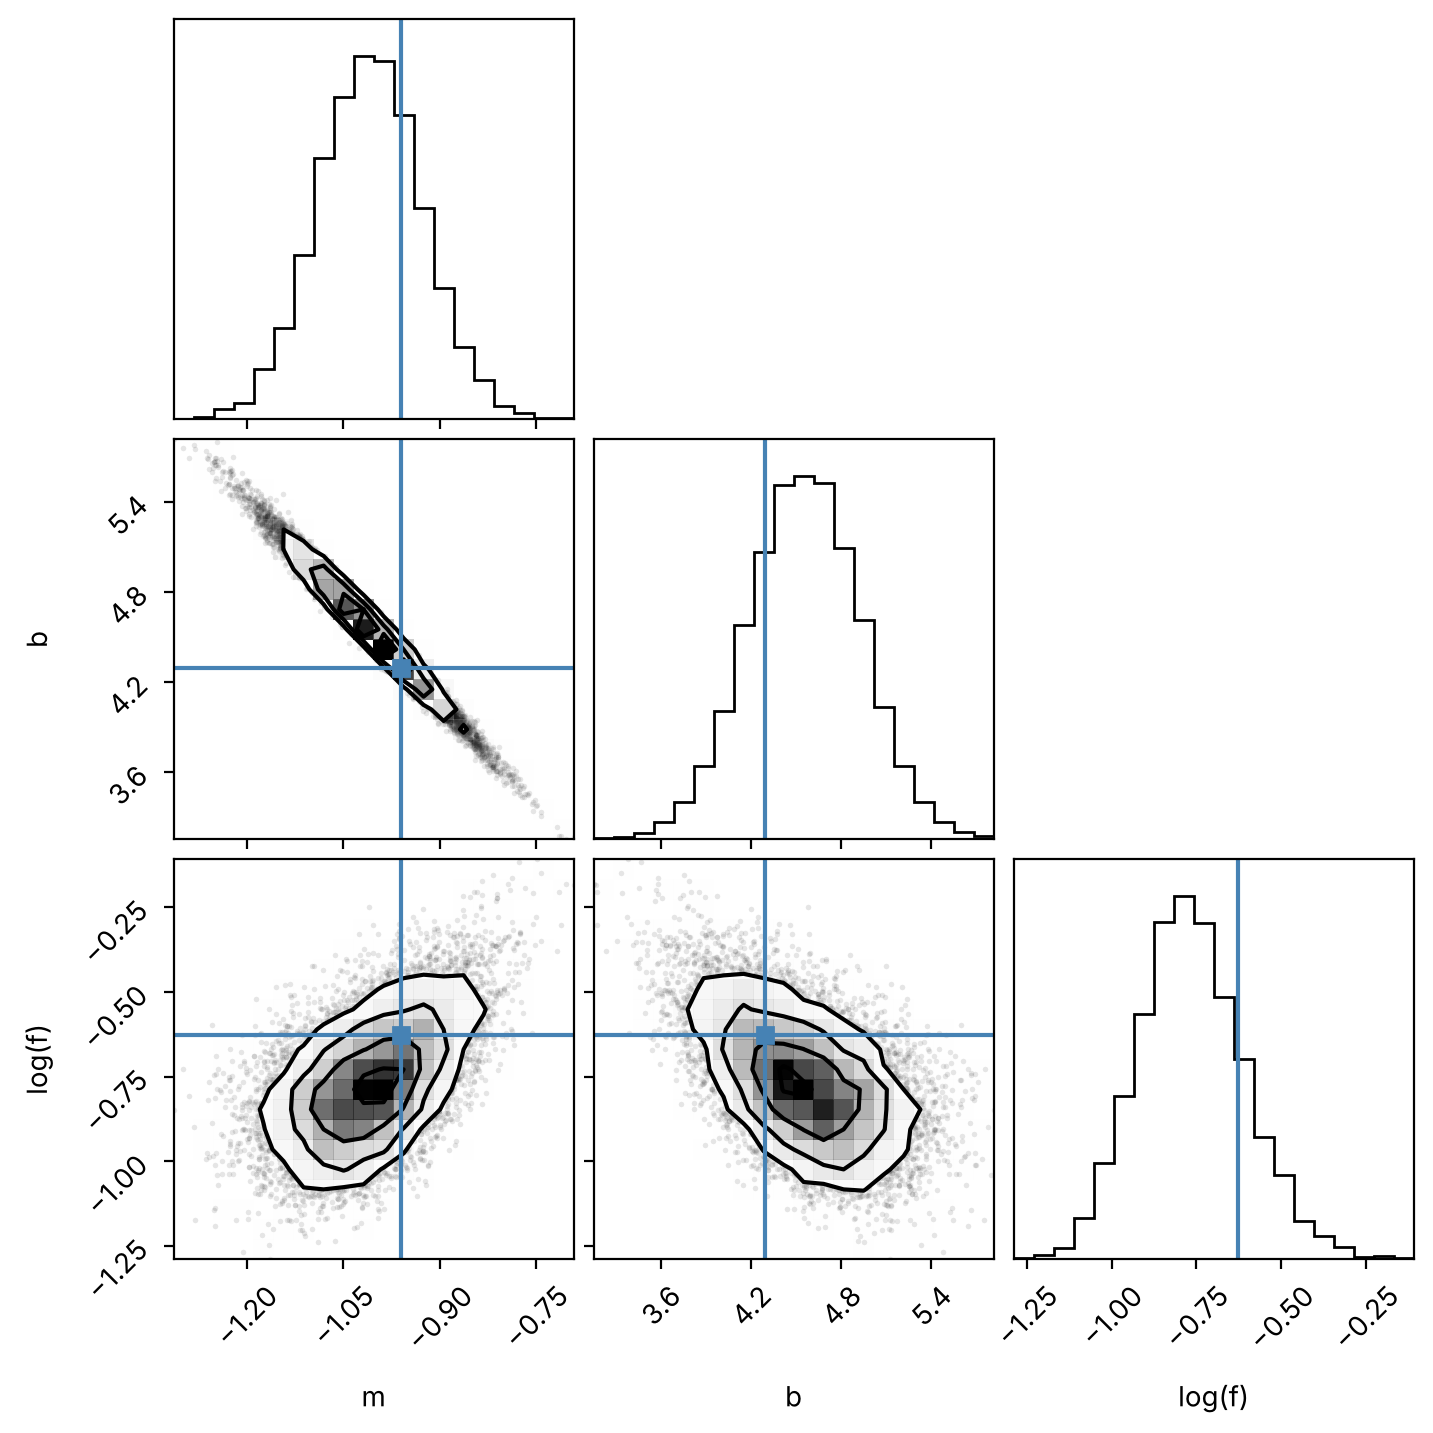

In [15]:
if IMA_CORNER:
    fig = corner.corner(flat_samples, labels=labels, truths=[m_true, b_true, np.log(f_true)])
    plt.show()
else:
    print("Za ovaj grafik potrebna je biblioteka corner.")

### 2i. Rezultati: medijana i 16./84. percentil

In [16]:
print(f"{'param':<8}{'prava':>9}{'najm. kv.':>18}{'emcee':>28}")
ls_vrednosti = [f"{w[0]:.3f} ± {np.sqrt(cov_ls[0,0]):.3f}", f"{w[1]:.3f} ± {np.sqrt(cov_ls[1,1]):.3f}", "—"]
prave = [m_true, b_true, np.log(f_true)]
for i in range(ndim):
    p16, p50, p84 = np.percentile(flat_samples[:, i], [16, 50, 84])
    print(f"{labels[i]:<8}{prave[i]:>9.3f}{ls_vrednosti[i]:>18}{f'{p50:.3f} (-{p50-p16:.3f}, +{p84-p50:.3f})':>28}")

param       prava         najm. kv.                       emcee
m          -0.959    -1.104 ± 0.016     -1.009 (-0.080, +0.080)
b           4.294     5.441 ± 0.091      4.554 (-0.367, +0.367)
log(f)     -0.627                 —     -0.773 (-0.147, +0.163)


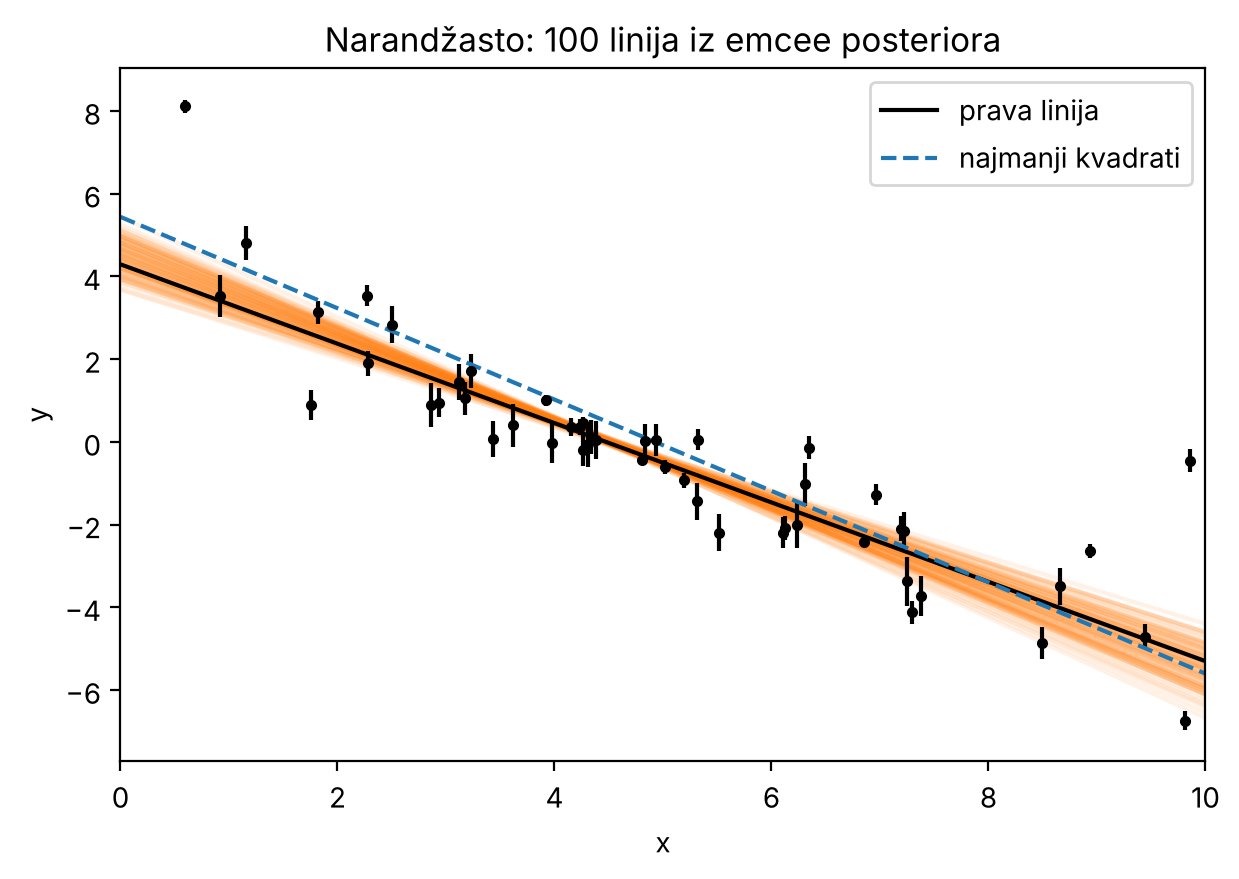

In [17]:
# Linije iz posteriora preko podataka
inds = np.random.randint(len(flat_samples), size=100)
for ind in inds:
    sample = flat_samples[ind]
    plt.plot(x0, np.dot(np.vander(x0, 2), sample[:2]), "C1", alpha=0.1)
plt.errorbar(x, y, yerr=yerr, fmt=".k", capsize=0)
plt.plot(x0, m_true * x0 + b_true, "k", label="prava linija")
plt.plot(x0, w[0]*x0 + w[1], "--", color="C0", label="najmanji kvadrati")
plt.legend(); plt.xlim(0, 10); plt.xlabel("x"); plt.ylabel("y")
plt.title("Narandžasto: 100 linija iz emcee posteriora"); plt.show()

## 3. Vreme autokorelacije τ

- Uzastopni uzorci su korelisani; τ je broj koraka posle kog je uzorak praktično nezavisan.
- **Efektivni broj uzoraka** je N/τ.
- Procena τ je pouzdana tek kada je lanac duži od **50τ**.

U nastavku je prikazano kako se procena τ menja sa dužinom lanca (koristi se lanac iz dela 2).

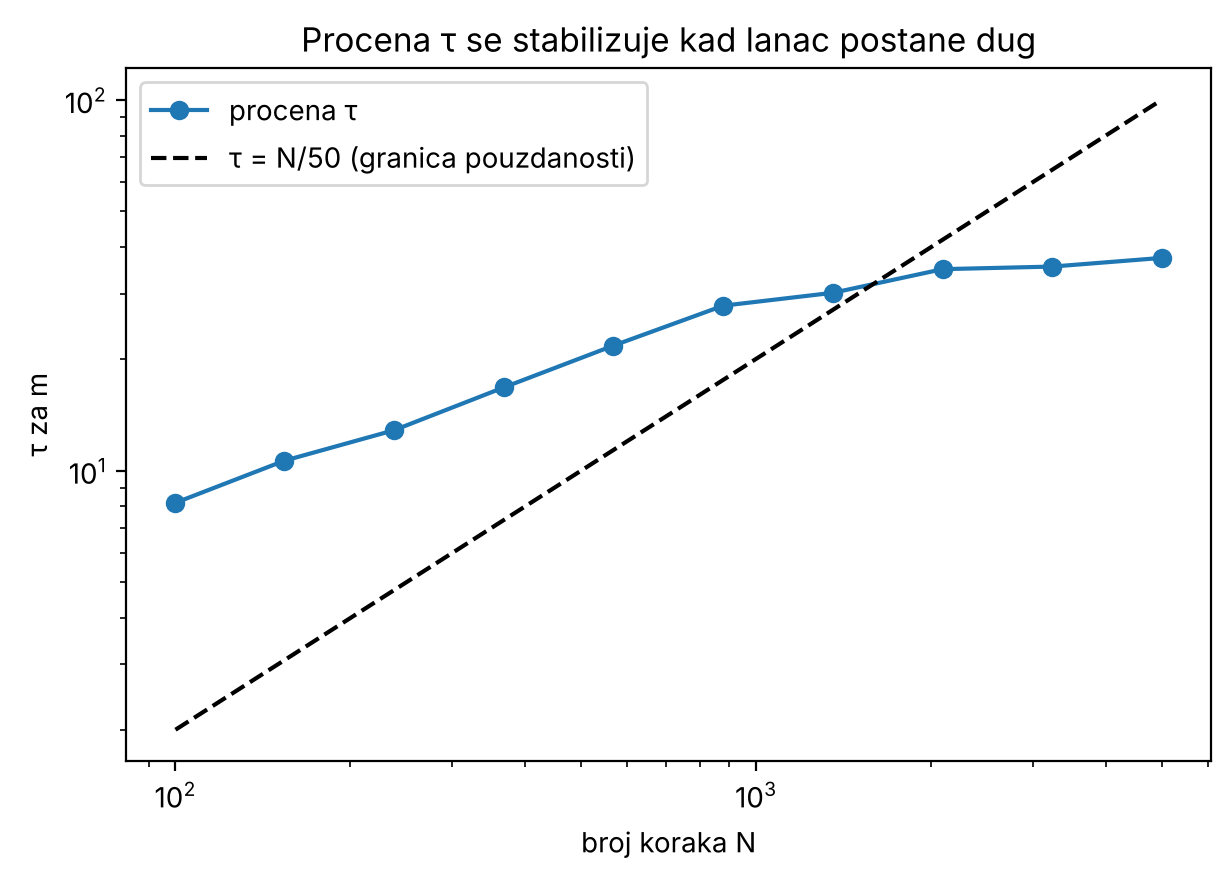

N =   100:  τ ≈   8.2   N/τ =   12.2  prekratko
N =   154:  τ ≈  10.6   N/τ =   14.5  prekratko
N =   238:  τ ≈  12.8   N/τ =   18.5  prekratko
N =   368:  τ ≈  16.8   N/τ =   22.0  prekratko
N =   568:  τ ≈  21.7   N/τ =   26.1  prekratko
N =   878:  τ ≈  27.8   N/τ =   31.5  prekratko
N =  1357:  τ ≈  30.2   N/τ =   45.0  prekratko
N =  2096:  τ ≈  34.9   N/τ =   60.0  pouzdano
N =  3237:  τ ≈  35.5   N/τ =   91.2  pouzdano
N =  5000:  τ ≈  37.5   N/τ =  133.5  pouzdano


In [18]:
chain_m = sampler.get_chain()[:, :, 0].T          # oblik (šetači, koraci) za parametar m
duzine = np.exp(np.linspace(np.log(100), np.log(chain_m.shape[1]), 10)).astype(int)
procene = [emcee.autocorr.integrated_time(sampler.get_chain()[:n, :, :1], tol=0)[0] for n in duzine]

plt.loglog(duzine, procene, "o-", label="procena τ")
plt.plot(duzine, duzine / 50.0, "--k", label="τ = N/50 (granica pouzdanosti)")
plt.xlabel("broj koraka N"); plt.ylabel("τ za m"); plt.legend()
plt.title("Procena τ se stabilizuje kad lanac postane dug"); plt.show()
for n, t in zip(duzine, procene):
    print(f"N = {n:5d}:  τ ≈ {t:5.1f}   N/τ = {n/t:6.1f}  {'pouzdano' if n > 50*t else 'prekratko'}")

In [19]:
# Prekratak lanac: emcee prijavljuje grešku (zaštitni mehanizam).
kratak = emcee.EnsembleSampler(32, 3, log_probability, args=(x, y, yerr))
kratak.run_mcmc(pos, 300)
try:
    kratak.get_autocorr_time()
except emcee.autocorr.AutocorrError as e:
    print("AutocorrError:", str(e)[:200], "...")
print("\nSa quiet=True dobija se gruba procena uz upozorenje:", np.round(kratak.get_autocorr_time(quiet=True), 1))

The chain is shorter than 50 times the integrated autocorrelation time for 3 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 6;
tau: [16.72920215 16.79639905 19.62971583]


AutocorrError: The chain is shorter than 50 times the integrated autocorrelation time for 3 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 6;
tau: [16.72920215 16.79639905 19.62971583] ...

Sa quiet=True dobija se gruba procena uz upozorenje: [16.7 16.8 19.6]


## 4. Dodatak: Hogg-ov mešavinski model sa emcee

**Pregled (Hogg, sekcija 3)**
- Svaka tačka je *dobra* (sa linije, verovatnoća 1−P_b) ili *loša* (iz široke pozadine sa sredinom Y_b i varijansom V_b).
- Model ima 5 parametara: b, m, P_b, Y_b, ln V_b. Od interesa su samo m i b, a ostali se **marginalizuju** (zanemarivanjem kolona).
- Za razliku od ručnog Metropolis–Hastings algoritma, veličinu koraka nije potrebno birati: emcee je određuje iz rasporeda šetača.

In [20]:
# Tabela 1 iz Hogg, Bovy, Lang (2010): x, y, sigma_y
T1 = np.array([[201,592,61],[244,401,25],[47,583,38],[287,402,15],[203,495,21],[58,173,15],
               [210,479,27],[202,504,14],[198,510,30],[158,416,16],[165,393,14],[201,442,25],
               [157,317,52],[131,311,16],[166,400,34],[160,337,31],[186,423,42],[125,334,26],
               [218,533,16],[146,344,22]], float)
hx, hy, hsy = T1.T

def mix_delovi(p, x, y, sy):
    b, m, Pb, Yb, lnVb = p
    Vb = np.exp(lnVb)
    dobra = (1 - Pb) * np.exp(-(y - m*x - b)**2 / (2*sy**2)) / np.sqrt(2*np.pi*sy**2)
    losa  = Pb * np.exp(-(y - Yb)**2 / (2*(Vb + sy**2))) / np.sqrt(2*np.pi*(Vb + sy**2))
    return dobra, losa

def mix_log_prior(p):
    b, m, Pb, Yb, lnVb = p
    if 0 < Pb < 1 and -5 < lnVb < 20 and -500 < b < 500 and -10 < m < 10 and 0 < Yb < 1000:
        return 0.0
    return -np.inf

def mix_log_probability(p, x, y, sy):
    lp = mix_log_prior(p)
    if not np.isfinite(lp):
        return -np.inf
    dobra, losa = mix_delovi(p, x, y, sy)
    return lp + np.sum(np.log(dobra + losa))

np.random.seed(0)
start = np.array([34, 2.24, 0.2, 450, np.log(5000)])   # grub početni pokušaj
pos_mix = start + 1e-3 * np.random.randn(32, 5)
s_mix = emcee.EnsembleSampler(32, 5, mix_log_probability, args=(hx, hy, hsy))
s_mix.run_mcmc(pos_mix, 10000, progress=True);

  0%|          | 0/10000 [00:00<?, ?it/s]

  1%|          | 69/10000 [00:00<00:14, 682.40it/s]

  1%|▏         | 138/10000 [00:00<00:14, 679.23it/s]

  2%|▏         | 206/10000 [00:00<00:14, 666.02it/s]

  3%|▎         | 323/10000 [00:00<00:11, 859.91it/s]

  4%|▍         | 442/10000 [00:00<00:09, 977.40it/s]

... (93 outputs left out)

 97%|█████████▋| 9724/10000 [00:10<00:00, 1009.56it/s]

 98%|█████████▊| 9827/10000 [00:11<00:00, 873.32it/s] 

 99%|█████████▉| 9926/10000 [00:11<00:00, 903.03it/s]

100%|██████████| 10000/10000 [00:11<00:00, 890.17it/s]

In [21]:
tau_mix = s_mix.get_autocorr_time()
print("τ:", np.round(tau_mix, 0), f"-> lanac = {10000/tau_mix.max():.0f} τ")
flat_mix = s_mix.get_chain(discard=int(3*tau_mix.max()), thin=int(tau_mix.max()/2), flat=True)

imena = ["b", "m", "P_b", "Y_b", "ln V_b"]
for i in range(3):
    p16, p50, p84 = np.percentile(flat_mix[:, i], [16, 50, 84])
    print(f"{imena[i]:<4} = {p50:.3f} (-{p50-p16:.3f}, +{p84-p50:.3f})")
print("\nHogg Vežba 1 (autor ručno izbacio tačke 1–4): m = 2.24 ± 0.11, b = 34 ± 18")

τ: [60. 59. 63. 73. 78.] -> lanac = 129 τ
b    = 31.984 (-19.146, +19.265)
m    = 2.258 (-0.116, +0.117)
P_b  = 0.279 (-0.115, +0.138)

Hogg Vežba 1 (autor ručno izbacio tačke 1–4): m = 2.24 ± 0.11, b = 34 ± 18


In [22]:
# Verovatnoća da je svaka tačka loša (uprosečeno preko uzoraka posteriora)
uz = flat_mix[np.random.randint(len(flat_mix), size=2000)]
p_losa = np.mean([mix_delovi(p, hx, hy, hsy)[1] / np.sum(mix_delovi(p, hx, hy, hsy), axis=0) for p in uz], axis=0)
for i in range(20):
    print(f"tačka {i+1:2d}: {p_losa[i]:4.2f}  " + "█" * int(round(p_losa[i]*20)))

tačka  1: 0.27  █████
tačka  2: 1.00  ████████████████████
tačka  3: 1.00  ████████████████████
tačka  4: 1.00  ████████████████████
tačka  5: 0.09  ██
tačka  6: 0.01  
tačka  7: 0.16  ███
tačka  8: 0.12  ██
tačka  9: 0.15  ███
tačka 10: 0.25  █████
tačka 11: 0.08  ██
tačka 12: 0.34  ███████
tačka 13: 0.18  ████
tačka 14: 0.05  █
tačka 15: 0.12  ██
tačka 16: 0.23  █████
tačka 17: 0.18  ████
tačka 18: 0.07  █
tačka 19: 0.06  █
tačka 20: 0.07  █


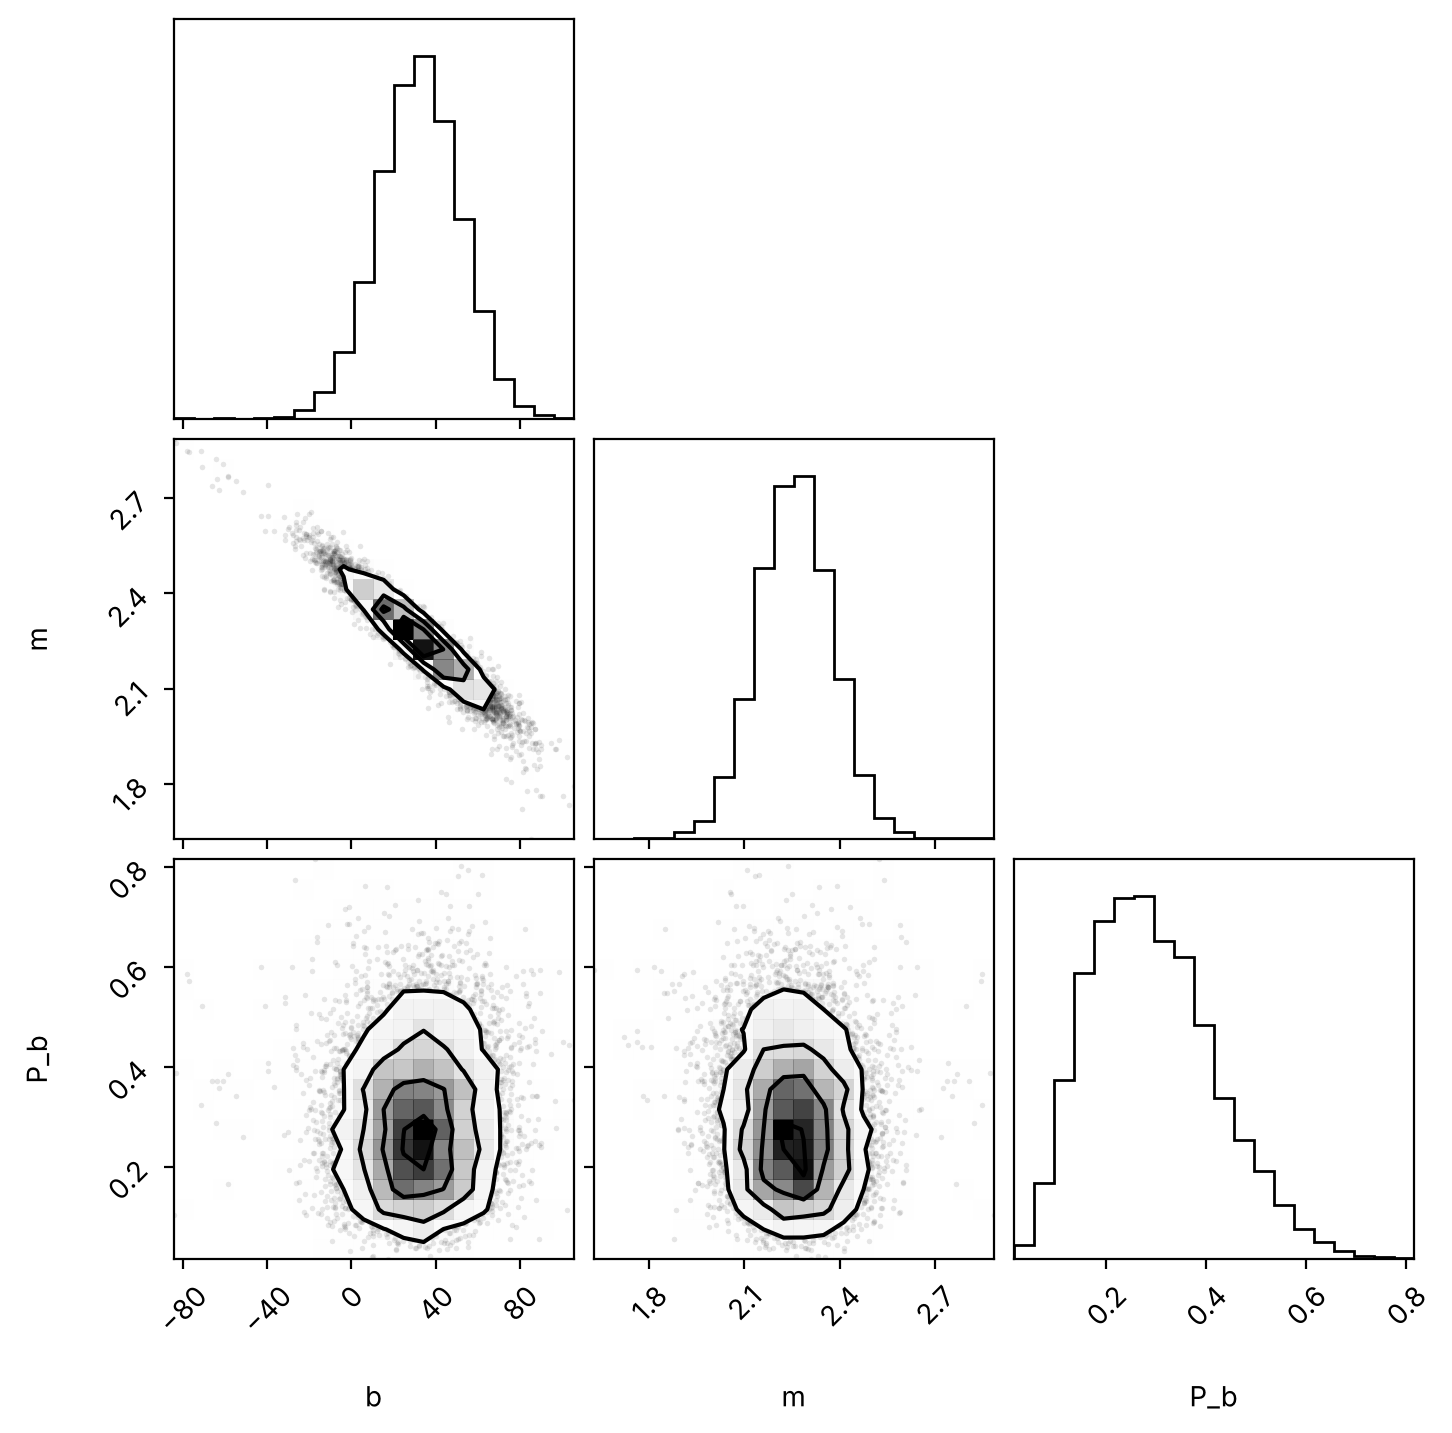

In [23]:
if IMA_CORNER:
    corner.corner(flat_mix[:, :3], labels=imena[:3]); plt.show()

## 5. Čuvanje napretka, automatsko zaustavljanje i blobs

- `HDFBackend` upisuje lanac u fajl tokom izvršavanja, pa se rezultati ne gube u slučaju prekida.
- Automatsko zaustavljanje: τ se proverava na svakih 100 koraka; lanac se zaustavlja kada je duži od 100τ **i** kada se τ promeni za manje od 1%.
- **Blobs** su dodatne vrednosti koje `log_prob` vraća pored ln verovatnoće (ovde: ln prior).

In [24]:
np.random.seed(42)

def log_prob_blob(theta):
    log_prior = -0.5 * np.sum((theta - 1.0) ** 2 / 100.0)
    log_prob = -0.5 * np.sum(theta**2) + log_prior
    return log_prob, log_prior          # druga vrednost = "blob"

coords = np.random.randn(32, 5)
nwalkers, ndim = coords.shape

filename = "tutorial.h5"
backend = emcee.backends.HDFBackend(filename)
backend.reset(nwalkers, ndim)           # briše postojeći fajl istog imena

sampler_b = emcee.EnsembleSampler(nwalkers, ndim, log_prob_blob, backend=backend)

max_n = 100000
index = 0
autocorr = np.empty(max_n)
old_tau = np.inf

for sample in sampler_b.sample(coords, iterations=max_n, progress=True):
    if sampler_b.iteration % 100:                       # provera samo na svakih 100 koraka
        continue
    tau = sampler_b.get_autocorr_time(tol=0)            # tol=0: procena se vraća i za kratak lanac
    autocorr[index] = np.mean(tau)
    index += 1
    converged = np.all(tau * 100 < sampler_b.iteration)          # uslov 1: lanac > 100τ
    converged &= np.all(np.abs(old_tau - tau) / tau < 0.01)      # uslov 2: τ stabilan (< 1%)
    if converged:
        break
    old_tau = tau

print(f"Zaustavljeno posle {sampler_b.iteration} koraka (od maksimalnih {max_n})")

  0%|          | 0/100000 [00:00<?, ?it/s]

  0%|          | 17/100000 [00:00<10:13, 162.87it/s]

  0%|          | 38/100000 [00:00<08:57, 185.86it/s]

  0%|          | 60/100000 [00:00<08:19, 200.08it/s]

  0%|          | 81/100000 [00:00<08:13, 202.32it/s]

  0%|          | 102/100000 [00:00<08:43, 190.85it/s]

... (317 outputs left out)

  6%|▌         | 5872/100000 [00:37<10:26, 150.27it/s]

  6%|▌         | 5890/100000 [00:37<09:55, 158.05it/s]

  6%|▌         | 5900/100000 [00:37<10:06, 155.27it/s]

Zaustavljeno posle 5900 koraka (od maksimalnih 100000)


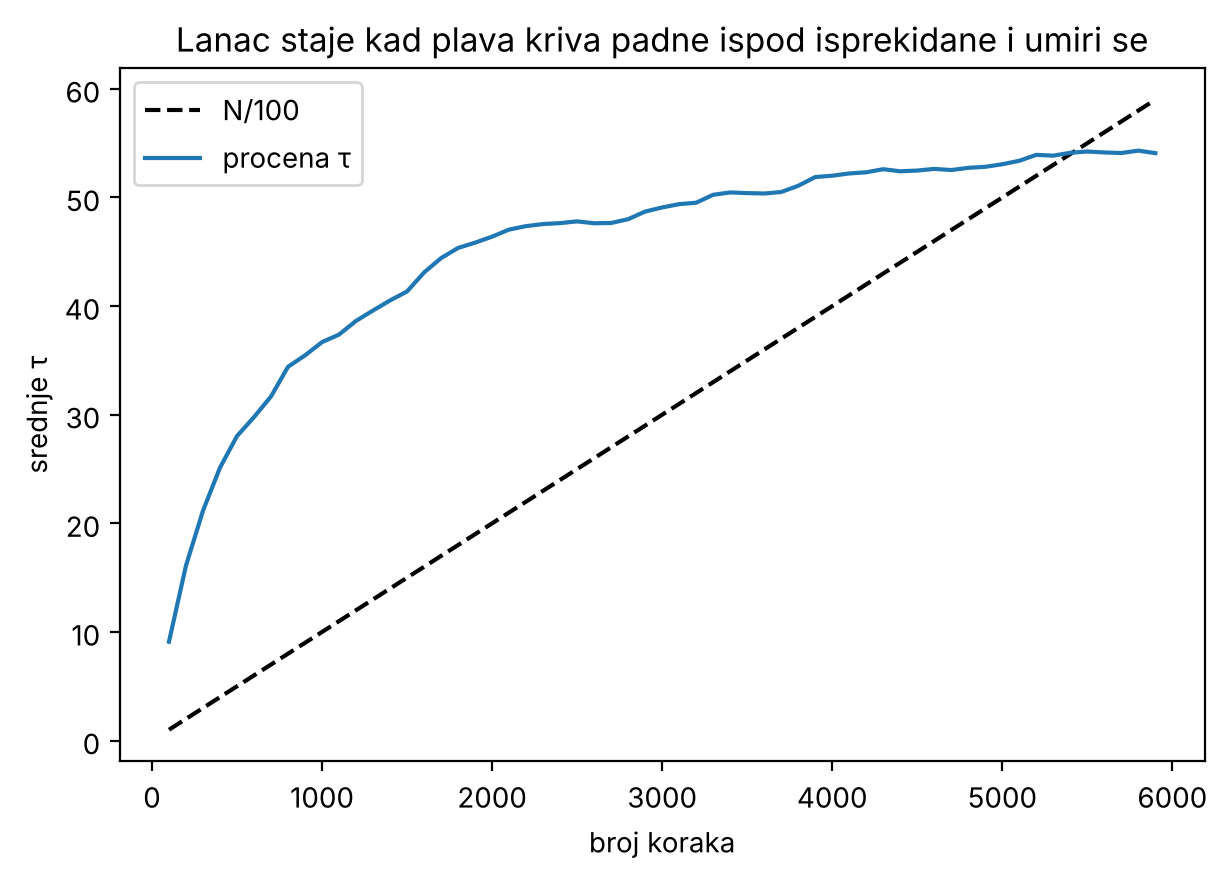

In [25]:
n = 100 * np.arange(1, index + 1)
plt.plot(n, n / 100.0, "--k", label="N/100")
plt.plot(n, autocorr[:index], label="procena τ")
plt.xlabel("broj koraka"); plt.ylabel("srednje τ"); plt.legend()
plt.title("Lanac staje kad plava kriva padne ispod isprekidane i umiri se"); plt.show()

In [26]:
# Čitanje iz fajla, nezavisno od originalnog samplera
reader = emcee.backends.HDFBackend(filename)
tau = reader.get_autocorr_time()
burnin = int(2 * np.max(tau))
thin = int(0.5 * np.min(tau))
samples_b = reader.get_chain(discard=burnin, flat=True, thin=thin)
log_prob_samples = reader.get_log_prob(discard=burnin, flat=True, thin=thin)
log_prior_samples = reader.get_blobs(discard=burnin, flat=True, thin=thin)   # blobs (ln prior)

print("burn-in:", burnin, " thin:", thin)
print("uzorci:", samples_b.shape, " ln prob:", log_prob_samples.shape, " ln prior (blobs):", log_prior_samples.shape)

burn-in: 117  thin: 24
uzorci: (7680, 5)  ln prob: (7680,)  ln prior (blobs): (7680,)


## 6. Paralelizacija

- Paralelizacija se isplati samo kada je `log_prob` **računski skup** (npr. kada sadrži PINN ili simulaciju).
- Postavljanje `OMP_NUM_THREADS=1` sprečava sukob NumPy-jeve paralelizacije sa paralelizacijom emcee-ja.
- Velike podatke ne treba prosleđivati kroz `args` (pakuju se pri svakom pozivu); bolje ih je čuvati kao globalnu promenljivu.

**Napomena za Windows:** `multiprocessing` u Jupyter-u na Windows-u obično ne radi sa funkcijama definisanim u samom notebook-u, pa ćelija ispod na Windows-u samo ispisuje poruku. Na Linux-u i macOS-u, kao i u `.py` skripti sa `if __name__ == "__main__":`, radi normalno.

In [27]:
import os, time, platform
os.environ["OMP_NUM_THREADS"] = "1"

def spor_log_prob(theta):
    # Veštački usporena funkcija koja simulira skup model
    t = time.time() + np.random.uniform(0.005, 0.008)
    while True:
        if time.time() >= t:
            break
    return -0.5 * np.sum(theta**2)

np.random.seed(42)
initial = np.random.randn(32, 5)
nsteps = 100

t0 = time.time()
emcee.EnsembleSampler(32, 5, spor_log_prob).run_mcmc(initial, nsteps)
serijski = time.time() - t0
print(f"Serijski: {serijski:.1f} s")

if platform.system() == "Windows":
    print("Windows: paralelni deo preskočen (videti napomenu iznad).")
else:
    from multiprocessing import Pool, cpu_count
    with Pool() as pool:
        t0 = time.time()
        emcee.EnsembleSampler(32, 5, spor_log_prob, pool=pool).run_mcmc(initial, nsteps)
        paralelno = time.time() - t0
    print(f"Paralelno ({cpu_count()} jezgara): {paralelno:.1f} s  ->  {serijski/paralelno:.1f}× brže")

Serijski: 21.2 s


Paralelno (2 jezgara): 11.5 s  ->  1.8× brže


## 7. Alternativni potezi (moves) — posterior sa dva maksimuma

- Podrazumevani `StretchMove` dobro radi za posterior sa jednim maksimumom, čak i kada je uzan i kos.
- Kada posterior ima **dva odvojena maksimuma**, šetači mogu da se zaglave; pomaže mešavina `DEMove` + `DESnookerMove`.

Test: 1D raspodela sa dva maksimuma (u −2 i +2). Tačan odgovor: polovina uzoraka levo, polovina desno.

StretchMove          τ =   40.0   udeo uzoraka desno: 0.49 (tačno: 0.50)
DEMove + DESnooker   τ =    6.7   udeo uzoraka desno: 0.51 (tačno: 0.50)


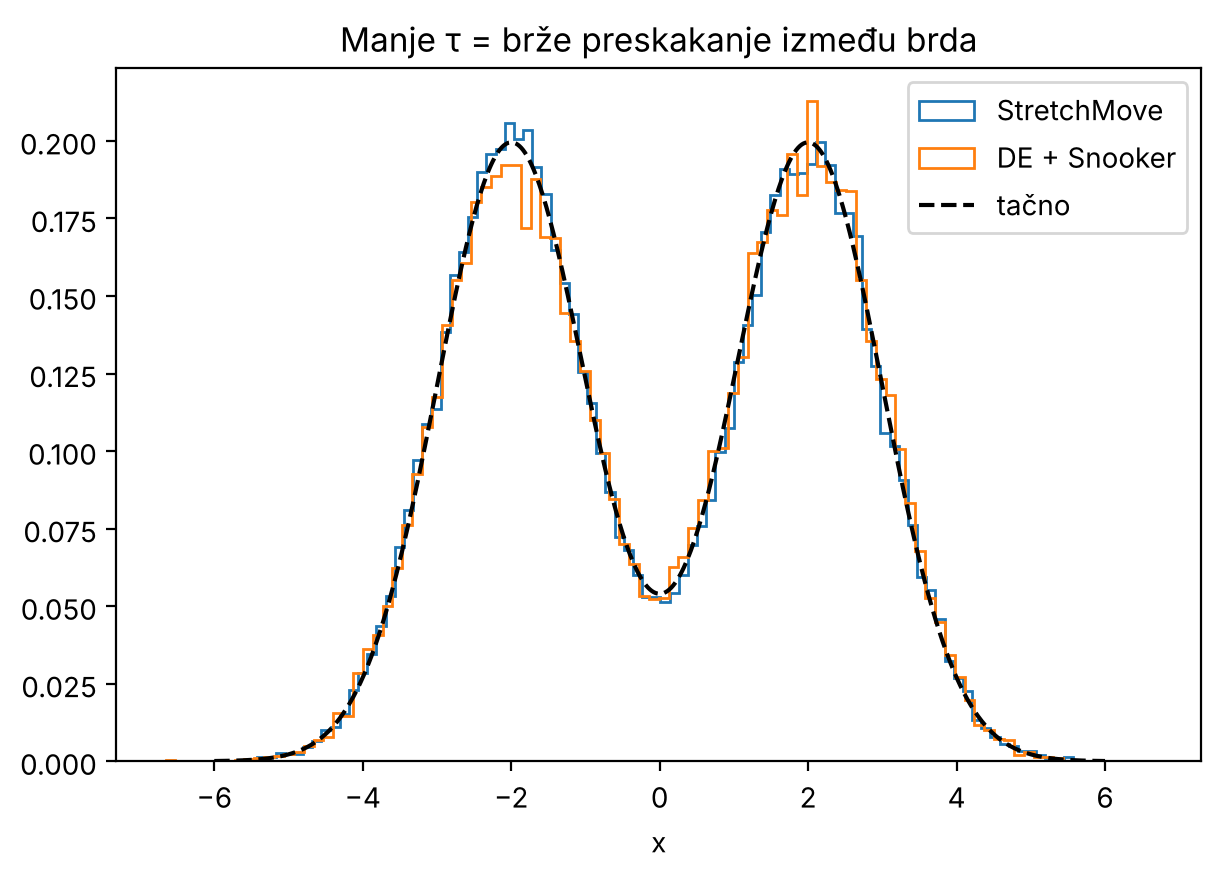

In [28]:
def logprob_dva_brda(x):
    return np.sum(np.logaddexp(-0.5 * (x - 2) ** 2, -0.5 * (x + 2) ** 2))   # ln(e^a + e^b) bez prelivanja

np.random.seed(589403)
init = np.random.randn(32, 1)

s_stretch = emcee.EnsembleSampler(32, 1, logprob_dva_brda)
s_stretch.run_mcmc(init, 5000)

s_de = emcee.EnsembleSampler(32, 1, logprob_dva_brda,
                             moves=[(emcee.moves.DEMove(), 0.8), (emcee.moves.DESnookerMove(), 0.2)])
s_de.run_mcmc(init, 5000)

for ime, s in [("StretchMove", s_stretch), ("DEMove + DESnooker", s_de)]:
    tau = s.get_autocorr_time(quiet=True)[0]
    desno = np.mean(s.get_chain(flat=True, discard=500) > 0)
    print(f"{ime:<20} τ = {tau:6.1f}   udeo uzoraka desno: {desno:.2f} (tačno: 0.50)")

t = np.linspace(-6, 6, 500)
tacno = np.exp(-0.5*(t-2)**2) + np.exp(-0.5*(t+2)**2); tacno /= (np.trapezoid if hasattr(np, "trapezoid") else np.trapz)(tacno, t)
plt.hist(s_stretch.get_chain(flat=True, discard=500)[:, 0], 100, histtype="step", density=True, label="StretchMove")
plt.hist(s_de.get_chain(flat=True, discard=500)[:, 0], 100, histtype="step", density=True, label="DE + Snooker")
plt.plot(t, tacno, "k--", label="tačno"); plt.legend(); plt.xlabel("x")
plt.title("Manje τ = brže preskakanje između brda"); plt.show()

## 8. Rezime i opšti šablon

**Redosled rada sa emcee-jem:**
1. Definisati **generativni model** → `log_likelihood`.
2. Definisati **prior** → `log_prior` (granice, fizička ograničenja).
3. `log_probability = log_prior + log_likelihood`, uz ručnu proveru na nekoliko tačaka.
4. Pronaći **maksimum** optimizatorom (`scipy.optimize.minimize` na `-log_probability`).
5. Postaviti šetače u **maloj okolini** maksimuma, uz `nwalkers ≥ 2·ndim` (obično 32 ili više).
6. `run_mcmc` → **trace plot** → `get_autocorr_time()` → provera da li je lanac duži od 50τ.
7. `get_chain(discard≈3τ, thin≈τ/2, flat=True)` → **percentili 16/50/84** → corner plot.
8. Pri objavljivanju navesti broj šetača, broj koraka, burn-in, thin, τ i stopu prihvatanja, uz citat Foreman-Mackey i sar. (2013).

| Simptom | Uzrok | Rešenje |
|---|---|---|
| greška: premalo šetača | nwalkers < 2·ndim | više šetača |
| greška: šetači linearno zavisni | svi su počeli iz iste tačke | dodati `1e-4*np.random.randn(...)` |
| stopa prihvatanja ≈ 0 | `log_prob` vraća `-inf`/`nan` na startu | proveriti `log_prob` u početnim tačkama |
| AutocorrError | lanac kraći od 50τ | duži lanac |
| sumnjivo male greške | neadekvatan model šuma | parametar za nepoznate greške (kao f) |

**Veza sa PINN-om:** emcee je pogodan za **mali broj parametara** (fizičke konstante, parametri šuma), a ne za sve težine neuronske mreže.